# ECG Heartbeat Classification — Exploratory Data Analysis
### Section 2.3 deliverables: MIT-BIH Arrhythmia Database

This notebook produces the following:
1. Raw ECG signal example
2. Example heartbeat from each class (N/S/V/F)
3. Class distribution
4. Subject/record distribution
5. Signal amplitude distribution
6. Examples of noisy ECG

It reads directly from `wfdb` (raw records) and from the `.npz`/`.csv` outputs
produced by `prepare_data.py`, `data_quality_check.py`. Run `prepare_data.py`
and `data_quality_check.py` first so the files referenced below exist.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

In [13]:
DATA_DIR = "./data"
QUALITY_DIR = "./data/quality"
LOCAL_MITDB_DIR = "../mit-bih-arrhythmia-database-1.0.0"
FS = 360


def load_raw_record(record_id, local_dir=None):
    if local_dir:
        return wfdb.rdrecord(os.path.join(local_dir, record_id))
    return wfdb.rdrecord(record_id, pn_dir="mitdb")


## 1. Raw ECG signal example
A short raw segment straight from one recording, before any filtering.

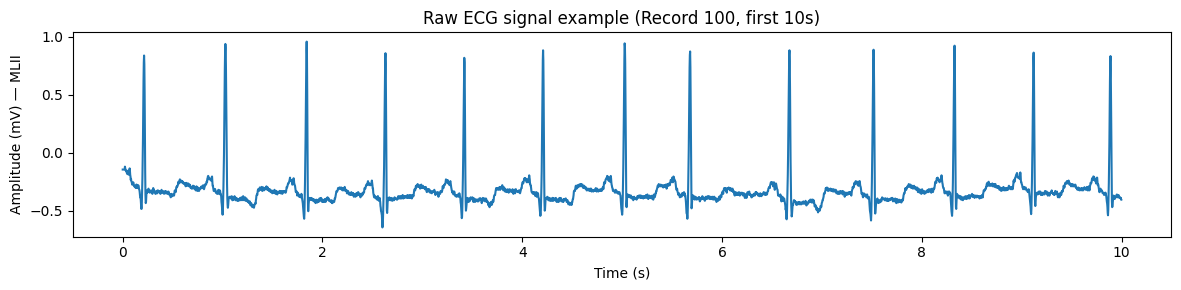

In [10]:
example_record = "100"
seconds = 10

rec = load_raw_record(example_record)
channel = 0
sig = rec.p_signal[: seconds * FS, channel]
t = np.arange(len(sig)) / FS

plt.figure(figsize=(12, 3))
plt.plot(t, sig)
plt.xlabel("Time (s)")
plt.ylabel(f"Amplitude (mV) — {rec.sig_name[channel]}")
plt.title(f"Raw ECG signal example (Record {example_record}, first {seconds}s)")
plt.tight_layout()
plt.show()

## 2. Example heartbeat from each class
One extracted, filtered, normalized beat window per class, pulled directly
from `train.npz` (the output of `prepare_data.py`).

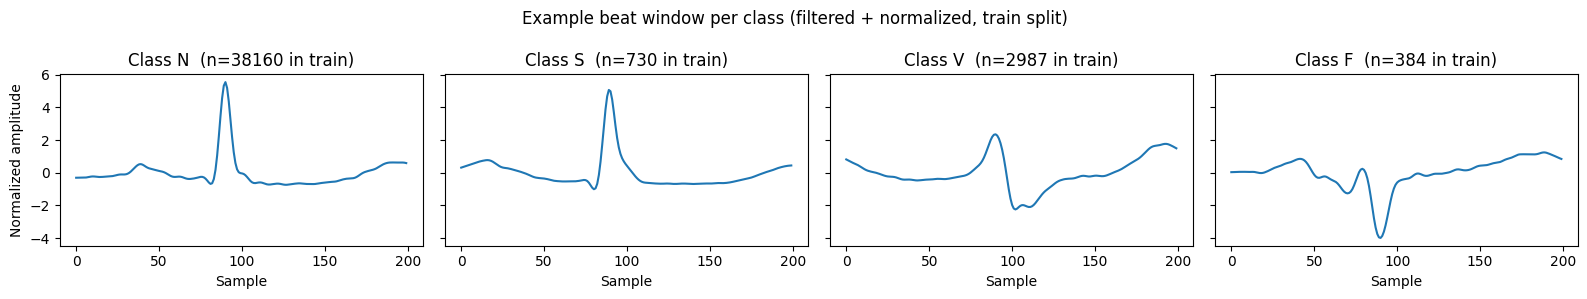

In [15]:
train = np.load(os.path.join(DATA_DIR, "train.npz"), allow_pickle=True)
X, y = train["X"], train["y"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, cls in zip(axes, ["N", "S", "V", "F"]):
    idx = np.where(y == cls)[0]
    if len(idx) == 0:
        ax.set_title(f"Class {cls}: none in train split")
        continue
    ax.plot(X[idx[0]])
    ax.set_title(f"Class {cls}  (n={len(idx)} in train)")
    ax.set_xlabel("Sample")
axes[0].set_ylabel("Normalized amplitude")
plt.suptitle("Example beat window per class (filtered + normalized, train split)")
plt.tight_layout()
plt.show()

## 3. Class distribution
Beat counts per class, across train/val/test.

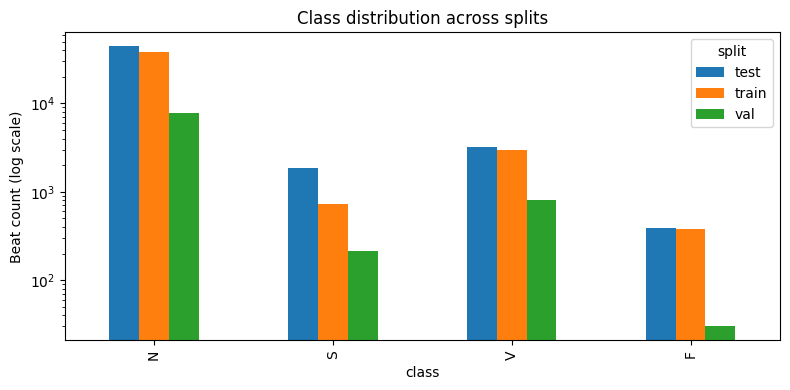

split,test,train,val
class,,,
N,44245,38160,7694
S,1837,730,214
V,3220,2987,801
F,388,384,30


In [18]:
class_df = pd.read_csv(os.path.join(DATA_DIR, "class_distribution.csv"))
pivot = class_df.pivot(index="class", columns="split", values="count").reindex(["N", "S", "V", "F"])

ax = pivot.plot(kind="bar", logy=True, figsize=(8, 4))
ax.set_ylabel("Beat count (log scale)")
ax.set_title("Class distribution across splits")
plt.tight_layout()
plt.show()

pivot

## 4. Subject/record distribution
How beats are spread across individual recordings within the training split.

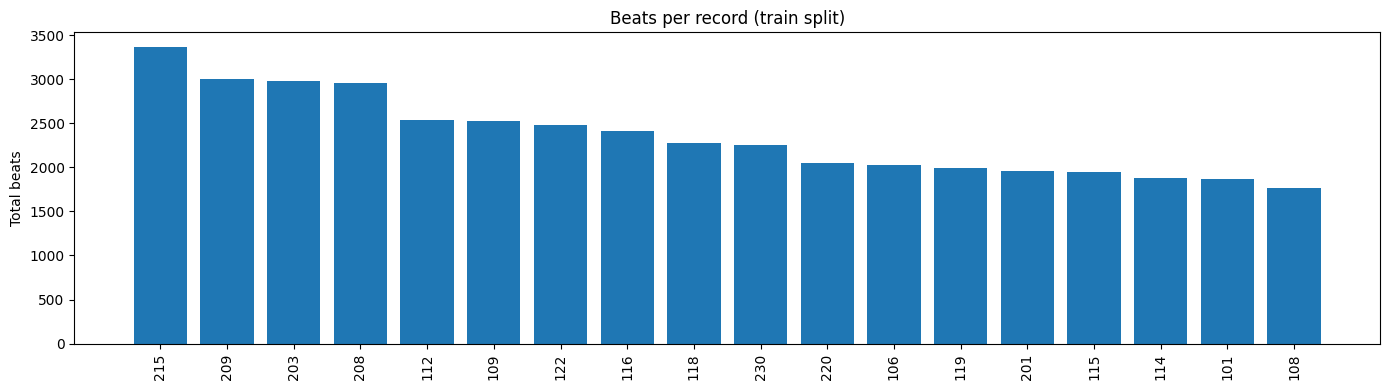

In [19]:
record_df = pd.read_csv(os.path.join(DATA_DIR, "record_distribution.csv"))
train_records = record_df[record_df["split"] == "train"].sort_values("total_beats", ascending=False)

plt.figure(figsize=(14, 4))
plt.bar(train_records["record_id"].astype(str), train_records["total_beats"])
plt.xticks(rotation=90)
plt.ylabel("Total beats")
plt.title("Beats per record (train split)")
plt.tight_layout()
plt.show()

## 5. Signal amplitude distribution
Two views: the raw voltage distribution within one example recording, and
the distribution of peak amplitude across all 48 records, showing how amplitude varies
patient-to-patient.

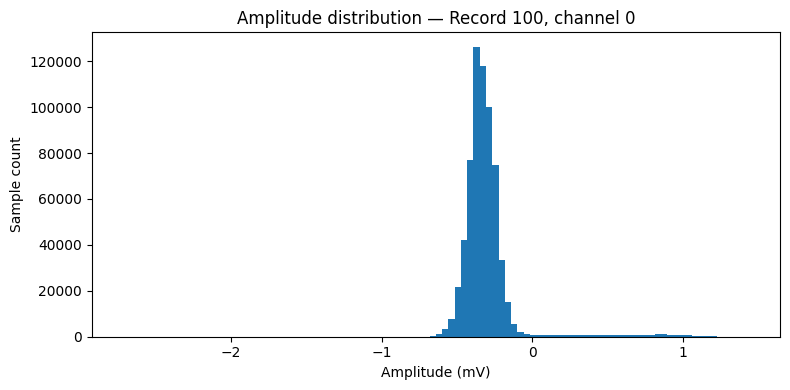

In [20]:
sig_full = load_raw_record(example_record).p_signal[:, 0]

plt.figure(figsize=(8, 4))
plt.hist(sig_full, bins=100)
plt.xlabel("Amplitude (mV)")
plt.ylabel("Sample count")
plt.title(f"Amplitude distribution — Record {example_record}, channel 0")
plt.tight_layout()
plt.show()

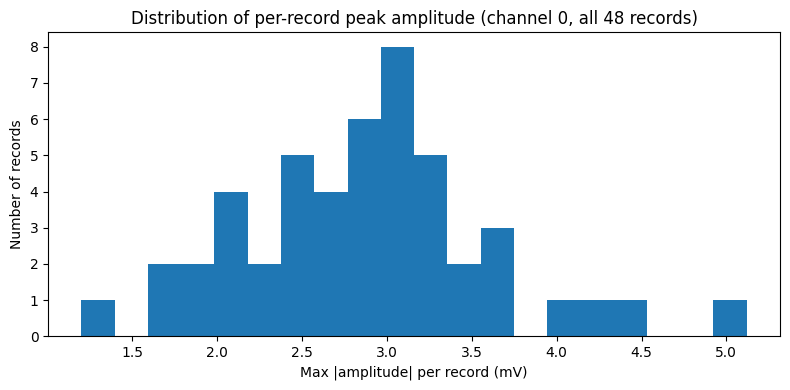

In [21]:
quality_df = pd.read_csv(os.path.join(QUALITY_DIR, "data_quality_report.csv"))

plt.figure(figsize=(8, 4))
plt.hist(quality_df["ch0_max_abs_mV"], bins=20)
plt.xlabel("Max |amplitude| per record (mV)")
plt.ylabel("Number of records")
plt.title("Distribution of per-record peak amplitude (channel 0, all 48 records)")
plt.tight_layout()
plt.show()

## 6. Examples of noisy ECG
A comparative plot: a relatively clean record vs. one with documented/flagged
noise.

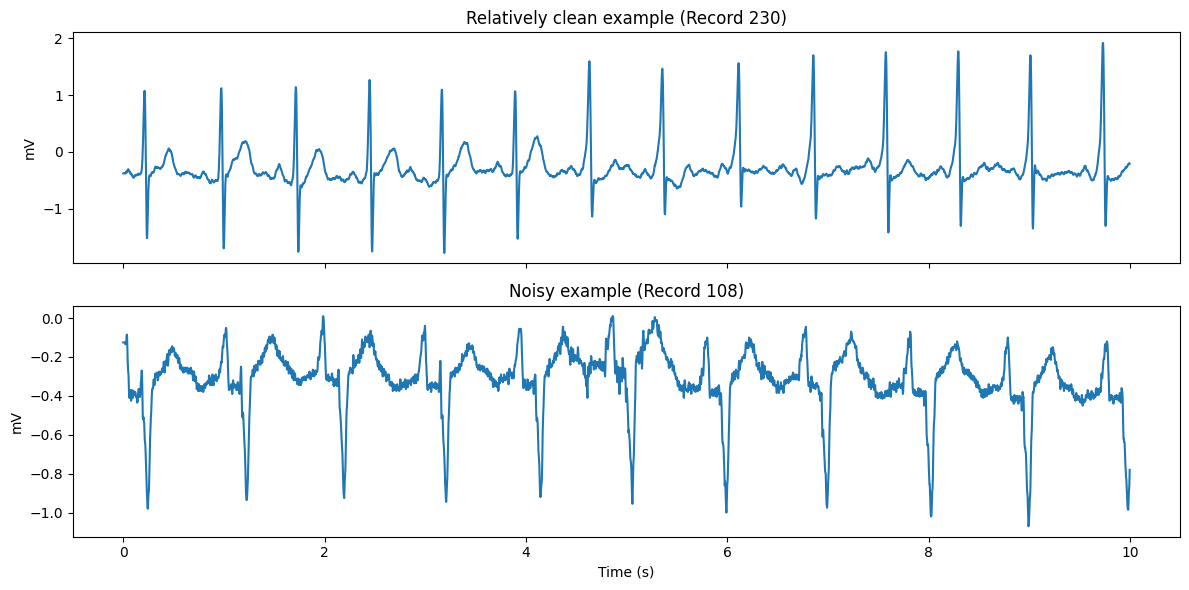

In [22]:
clean_example = "230"
noisy_example = "108"

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, rid, label in zip(
    axes,
    [clean_example, noisy_example],
    [f"Relatively clean example (Record {clean_example})", f"Noisy example (Record {noisy_example})"],
):
    rec = load_raw_record(rid)
    seg = rec.p_signal[: seconds * FS, 0]
    t = np.arange(len(seg)) / FS
    ax.plot(t, seg)
    ax.set_title(label)
    ax.set_ylabel("mV")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Summary
- Raw signal, per-class beat shapes, class imbalance, record-level beat
  distribution, amplitude distribution, and a clean-vs-noisy comparison are
  all shown above.
- These plots pair with the quantitative findings in Section 2.4
  (Data Quality) and Section 3.6 (Class Imbalance) of the report.